# Trabajo RFA - NIHChestXR
## Héctor Bernal Martí

## Índice

- Configuración y declaraciones
- Definición del problema
- Sistema
- Datos
    - Carga del dataset
    - Muestra de datos
    - Distribución de los datos
    - Partición por paciente
- Estrategias de fine-tuning (DenseNet121)
    - Aumento de datos
    - Función de pérdida
    - Métricas de evaluación
    - Completo
    - Capas intermedias
    - Cabecera
    - Comparativa
- Experimento: *No Finding* derivado
    - Completo
    - Capas intermedias
    - Cabecera
    - Comparativa
- Promedio de modelos
- Otros experimentos
    - Planificador: calendario fijo
    - Aumento de datos fuerte
    - Inicialización desde la cabecera (LP-FT)
    - Reflejo horizontal
    - Comparación
- Comparación con la literatura
- Bibliografía

### Configuración y declaraciones para el trabajo

Para este trabajo se han utilizado los siguientes paquetes con sus respectivas versiones (`Python 3.14.8` & `pip 26.2.1`):

- *torch* `2.14.1`
- *torchvision* `0.29.1`
- *timm* `1.0.30`
- *datasets* `5.0.1`
- *numpy* `2.5.2`
- *pandas* `3.0.6`
- *scikit-learn* `1.9.1`
- *matplotlib* `3.11.2`
- *prettytable* `3.18.0`
- *ipykernel* `7.4.0`

In [2]:
# === Imports ===

import numpy as np
import matplotlib.pyplot as plt
from matplotlib.gridspec import GridSpec
from datasets import load_dataset

# Lógica de Machine Learning (datos, entrenamiento, búsqueda de hiperparámetros, evaluación...): ver rfa_lib.py
from rfa_lib import *

### Definición del problema

Este problema consta en una base de datos de pruebas de radiografías (*X-Ray*) de tórax del NIH (*National Institutes of Health*).
Se trata de un problema multicapa multietiqueta en el cual se busca detectar hasta 14 patologías torájicas comunes y en caso de que no haya ninguna se marca como no encontrada (*No Finding*), siendo un total de 15 clases diferentes.
En la base de datos también se hayan sexo (*sex*) y edad (*age*) del paciente. Pueden haber varias pruebas (*scan_id*) por paciente (*patient_id*).

In [3]:
# === Problem Definition ===

LABELS_DICT = {
    0: "No Finding",
    1: "Atelectasis",
    2: "Cardiomegaly",
    3: "Effusion",
    4: "Infiltration",
    5: "Mass",
    6: "Nodule",
    7: "Pneumonia",
    8: "Pneumothorax",
    9: "Consolidation",
    10: "Edema",
    11: "Emphysema",
    12: "Fibrosis",
    13: "Pleural Thickening",
    14: "Hernia",
}
LABELS = list(LABELS_DICT.values())
C = len(LABELS_DICT)
SEED = 42
DEVICE = "cuda"

## Sistema

A continuación se muestra el sistema sobre el que se va a trabajar para este proyecto.

In [18]:
!nvidia-smi

Mon Oct 26 22:41:08 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 615.78.08              KMD Version: 615.78.08     CUDA UMD Version: 13.4     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  NVIDIA GeForce RTX 3060        Off |   00000000:06:00.0  On |                  N/A |
| 63%   45C    P8             20W /  170W |    2748MiB /  12288MiB |      2%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Datos

### Carga del dataset

A continuación vemos todos los datos de entrada del dataset y el tamaño de este, un total de 112,120 entradas.

In [4]:
# === Data ===

# https://huggingface.co/datasets/chehablab/NIHChestXR
DATASET_OWNER = "chehablab"
DATASET_NAME = "NIHChestXR"
ds = load_dataset(DATASET_OWNER + "/" + DATASET_NAME, split="train")

# Tabla sin la columna de imágenes (para el análisis de datos no hace falta cargarlas en memoria)
df = ds.select_columns(['patient_id', 'scan_id', 'age', 'sex', 'labels']).to_pandas()
print(f"Dataset Headers: {ds.column_names}")
print(f"Imágenes: {len(ds)}")

Dataset Headers: ['patient_id', 'scan_id', 'image', 'age', 'sex', 'labels']
Imágenes: 112120


### Muestra de datos

A continuación podemos ver un ejemplo de una de las radiografias que contiene el dataset, en este caso clasificado con enfisema (*emphysema*).

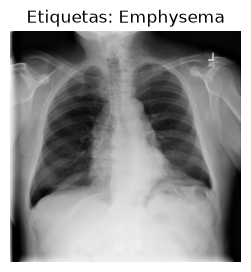

In [11]:
sample = ds[26]
plt.figure(figsize=(3, 3))
plt.title(f"Etiquetas: {', '.join(LABELS_DICT[l] for l in sample['labels'])}")
plt.imshow(sample['image'], cmap='gray', vmin=0, vmax=255)
plt.axis('off')
plt.show()
plt.close()

### Distribución de los datos

A continuación se muestra gráficamente la distribución de los datos.

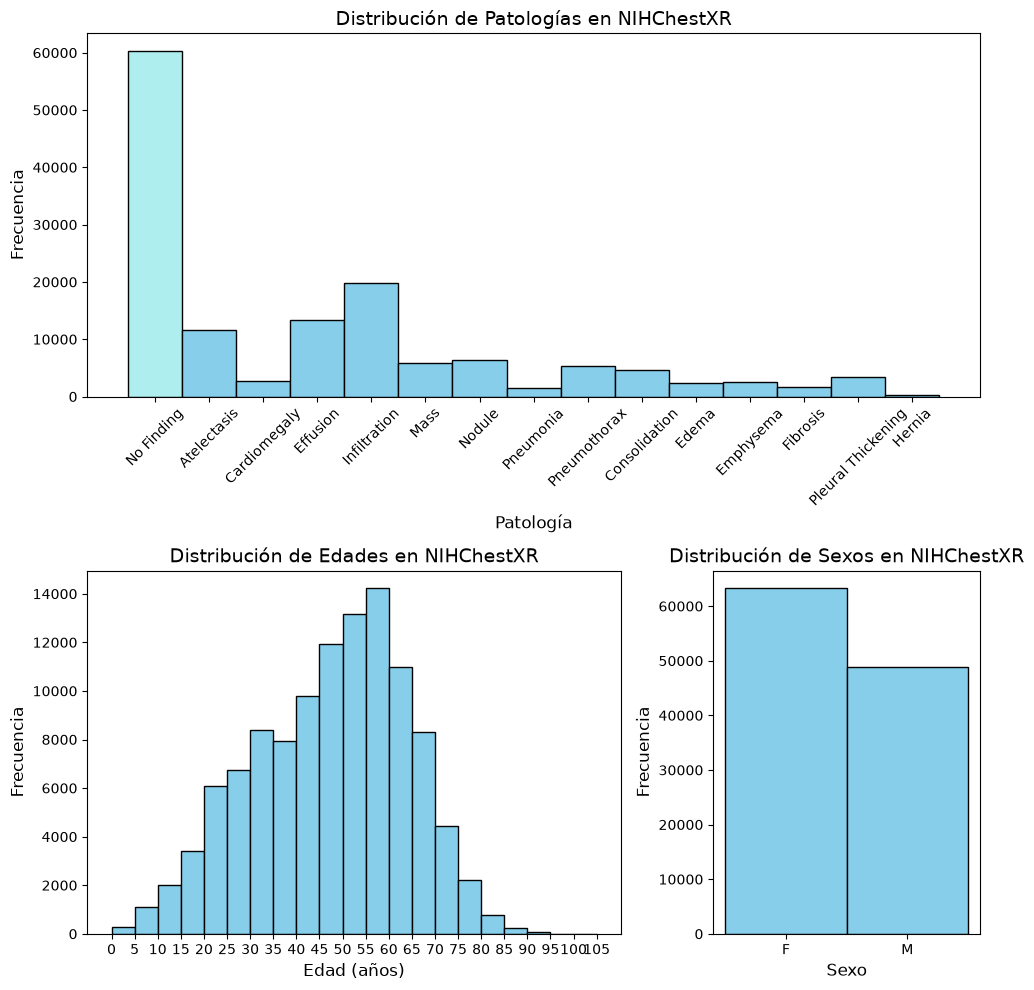

In [21]:
fig = plt.figure(figsize=(10, 10))
gs = GridSpec(2, 2, figure=fig, width_ratios=[2, 1])

# Patologías: fila superior, ocupa las dos columnas
ax1 = fig.add_subplot(gs[0, :])
ax1.set_title(f'Distribución de Patologías en {DATASET_NAME}', fontsize=14)
n, edges, patches = ax1.hist(df['labels'].explode(), bins=C, color='skyblue', edgecolor='black', range=(0, C-1))
# Resaltar la barra correspondiente a 'No Finding' en rojo
idx_nf = list(LABELS).index('No Finding')
patches[idx_nf].set_facecolor('paleturquoise')
# Centrar las etiquetas en el eje x
centros = (edges[:-1] + edges[1:]) / 2
ax1.set_xticks(centros)
ax1.set_xticklabels(LABELS, rotation=45)
ax1.set_xlabel('Patología', fontsize=12)
ax1.set_ylabel('Frecuencia', fontsize=12)

# Edad: abajo a la izquierda, bins de 5 años desde 0 hasta la edad máxima
ax2 = fig.add_subplot(gs[1, 0])
ax2.set_title(f'Distribución de Edades en {DATASET_NAME}', fontsize=14)
bins_edad = np.arange(0, 110, 5)
ax2.hist(df['age'], bins=bins_edad, color='skyblue', edgecolor='black')
ax2.set_xticks(bins_edad)
ax2.set_xticklabels(bins_edad)
ax2.set_xlabel('Edad (años)', fontsize=12)
ax2.set_ylabel('Frecuencia', fontsize=12)

# Sexo: abajo a la derecha
ax3 = fig.add_subplot(gs[1, 1])
ax3.set_title(f'Distribución de Sexos en {DATASET_NAME}', fontsize=14)
n, edges, patches = ax3.hist(df['sex'], bins=2, color='skyblue', edgecolor='black')
centros = (edges[:-1] + edges[1:]) / 2
ax3.set_xticks(centros)
ax3.set_xticklabels(['F', 'M'])
ax3.set_xlabel('Sexo', fontsize=12)
ax3.set_ylabel('Frecuencia', fontsize=12)

plt.tight_layout()
plt.show()
plt.close()

### Partición por paciente

Se ha decidido hacer una partición por paciente en lugar de por imágenes. *¿Por qué se hace esto?*

Haciendo una partición por pacientes permite que el modelo aprenda patrones reconocibles de cada patología, ya que un paciente suele tener varias radiografías.

Si se realizase particiones por imagen el modelo podría aprender simplemente a relacionar los pacientes que ve en tests con los que ha visto en training en lugar de aprender sobre la patología.

**Como deseamos aprender sobre las *patologías* y no sobre los *pacientes*, realizamos la partición por pacientes.**

In [6]:
datos = preparar_datos(ds)

┌───────────┬───────────────┬────────────┬───────┬────────┐
│           │ Entrenamiento │ Validación │  Test │ Total  │
├───────────┼───────────────┼────────────┼───────┼────────┤
│  Imágenes │     78996     │   16321    │ 16803 │ 112120 │
│ Pacientes │     21563     │    4621    │  4621 │ 30805  │
└───────────┴───────────────┴────────────┴───────┴────────┘


## Estrategias de fine-tuning (DenseNet121)


Se ha elegido **DenseNet121** como arquitectura base por estas razones:

- **Referencia en radiografía de tórax.** Es la arquitectura de CheXNet (Rajpurkar et al., 2017), que obtuvo resultados al nivel de radiólogos en ChestX-ray14, y se ha convertido en la línea base habitual para este dataset. Eso permite comparar los resultados con otros trabajos.
- **Eficiente en parámetros.** Con unos 7 millones de parámetros entrenables es mucho más ligera que otras redes de rendimiento similar, lo que permite entrenarla varias veces con distintos hiperparámetros y estrategias.
- **Se adapta bien al fine-tuning por etapas.** Su estructura en bloques densos (`denseblock1` a `denseblock4`) permite congelar o entrenar partes concretas de la red. Esto es la base de las tres estrategias de fine-tuning que se comparan: completo, capas intermedias y solo cabecera.
- **Pre-entrenada en ImageNet.** Se parte de pesos de ImageNet y se adapta la primera capa a 1 canal, porque las radiografías son en escala de grises. Aprovechar características visuales genéricas (bordes, texturas) reduce la cantidad de datos y de épocas necesarias.


### Aumento de datos

Son transformaciones aleatorias que se aplican **solo a las imágenes de entrenamiento**, en cada época. Así el modelo ve versiones ligeramente distintas de cada radiografía y no la memoriza (**regularización**). **Validación y test usan siempre la imagen sin perturbar**. Todas las variantes comparten la base: escala de grises (1 canal), conversión a tensor y normalización.

| Valor | Transformaciones | Idea |
|---|---|---|
| `none` | Ninguna | Línea base, sin aumento. |
| `light` | Rotación aleatoria ±5° y traslación aleatoria de hasta el 3 % | Simula pequeñas diferencias de posición del paciente respecto al equipo, sin cambiar el aspecto de la imagen. |
| `medium` | Rotación ±10°, traslación de hasta el 5 %, escala 0,95–1,05, y brillo y contraste ±20 % | Añade variación de zoom y de exposición entre equipos y hospitales. |
| `strong` | Recorte aleatorio redimensionado (80–100 % del área, proporción 0,9–1,1), rotación ±10°, traslación 5 %, y brillo y contraste ±30 % | Perturbación fuerte. Obliga al modelo a reconocer la patología aunque se vea solo una parte de la imagen. |
| `strong_flip` | Todo lo de `strong` más volteo horizontal | Duplica la variedad de imágenes. Tiene el inconveniente de que el corazón pasa al lado derecho, algo anatómicamente poco realista. |


### Función de pérdida

El problema es **multietiqueta**: una radiografía puede tener varias patologías a la vez. Por eso cada clase tiene su propia salida con sigmoide, y se entrena con la entropía cruzada binaria (BCE) de cada clase, promediada. Las tres opciones difieren solo en cuánto pesa el error en los casos positivos de cada clase.

**Por qué hace falta ponderar.** Las clases están muy desbalanceadas. Patologías como Hernia o Pneumonia tienen muy pocos positivos frente a miles de negativos. Con BCE sin pesos, el modelo puede minimizar la pérdida prediciendo casi siempre «ausente» y apenas aprende las clases raras.

| Valor | Cómo funciona | Efecto |
|---|---|---|
| `bce` | BCE estándar, sin pesos. | Todos los errores cuentan igual. Las clases raras quedan poco atendidas. |
| `pw` (*positive weight*) | Cada positivo de una clase se multiplica por `negativos / positivos` de esa clase (calculado solo con train). | Equilibra por completo las clases. Es agresivo: las clases raras reciben pesos enormes, lo que da gradientes grandes e inestables y puede empeorar el ranking global. |
| `pw_sqrt` | Igual que `pw`, pero con la **raíz cuadrada** del peso. | Término medio. Compensa el desbalanceo sin sobrecorregirlo. |

### Métricas de evaluación

**AUROC (área bajo la curva ROC).** Se calcula **por patología**, tratando cada una como un problema binario (presente o ausente) con la probabilidad que da el modelo. La curva ROC representa, al variar el umbral de decisión, la tasa de verdaderos positivos (sensibilidad) frente a la tasa de falsos positivos (1 − especificidad). El AUROC es el área bajo esa curva y tiene una interpretación directa:

> Es la probabilidad de que, al elegir al azar una radiografía con la patología y otra sin ella, el modelo dé una probabilidad **mayor** a la que sí la tiene.

- **0,5**: el modelo no distingue nada (azar).
- **1,0**: separación perfecta.
- **< 0,5**: peor que el azar (ordena al revés).

**mAUC (AUROC medio).** Es la media aritmética del AUROC de las **14 patologías** y es la métrica principal de todo el trabajo. En la variante de 15 salidas, «No Finding» queda fuera de la media para que ambas variantes sean comparables. Si una clase no tuviera positivos o negativos en la partición, se omite de la media.

### Completo

**Búsqueda de hiperparámetros (completo).** Búsqueda voraz (un parámetro cada vez) con 25.000 imágenes de train, 8.000 de validación y 4 épocas con planificador coseno. Se optimiza el mAUC de validación y los 2 mejores candidatos se confirman con 3 semillas.

| Parámetro | Valores probados |
|---|---|
| lr | 3e-5, 1e-4, 3e-4 |
| wd | 1e-2, 5e-2 |
| aug | none, light, medium |
| loss | bce, pw, pw_sqrt |

El mejor resultado fue `lr=3e-4`, `wd=1e-2`, `aug=light` y `loss=pw_sqrt`, con un mAUC de validación de 0,8219 ± 0,0026 (media de 3 semillas). 

Con estos parámetros entrenamos el modelo definitivo con **todo el conjunto de entrenamiento** (21.563 pacientes, 78.996 imágenes), no con el subconjunto de la búsqueda. Se usa AdamW con precisión mixta (fp16) y un máximo de 20 épocas. El lr sigue un planificador *plateau*: calentamiento lineal durante la primera época y después se multiplica por 0,3 cuando el mAUC de validación no mejora en 1 época. Hay parada temprana tras 5 épocas sin mejorar. En cada época se evalúa el mAUC de validación y se conservan los pesos de la mejor época, que son los que se usan después. El test no se toca hasta la evaluación final. El entrenamiento se detuvo en la época 13, con la mejor en la 8, y alcanzó un mAUC de validación de 0,8332.

In [23]:
ESPACIO_FULL = {
    'lr': [3e-5, 1e-4, 3e-4],
    'wd': [1e-2, 5e-2],
    'aug': ['none', 'light', 'medium'],
    'loss': ['bce', 'pw', 'pw_sqrt'],
}
mejores_full = buscar_hiperparametros(datos, construir_config(capas='completo'), ESPACIO_FULL, nombre='full')

[1] {'lr': 3e-05, 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.7694
[2] {'lr': 0.0001, 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.8043
[3] {'lr': 0.0003, 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.8148
>> mejor lr: 0.0003
[4] {'lr': 0.0003, 'wd': 0.05, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.8139
>> mejor wd: 0.01
[5] {'lr': 0.0003, 'wd': 0.01, 'aug': 'light', 'loss': 'bce'} -> val mAUC 0.8174
[6] {'lr': 0.0003, 'wd': 0.01, 'aug': 'medium', 'loss': 'bce'} -> val mAUC 0.8167
>> mejor aug: light
[7] {'lr': 0.0003, 'wd': 0.01, 'aug': 'light', 'loss': 'pw'} -> val mAUC 0.8093
[8] {'lr': 0.0003, 'wd': 0.01, 'aug': 'light', 'loss': 'pw_sqrt'} -> val mAUC 0.8249
>> mejor loss: pw_sqrt

Resultados de la búsqueda (validación):
┌───┬────────┬──────┬────────┬─────────┬──────────┬─────────────┐
│ # │   lr   │  wd  │  aug   │   loss  │ val_mAUC │ mejor_epoca │
├───┼────────┼──────┼────────┼─────────┼──────────┼─────────────┤
│ 1 │ 0.0003 │ 0.01 │ light  │ pw

In [24]:
full = entrenar(datos, mejores_full, nombre='full')

ep  0 | loss train 0.4547 | val mAUC 0.7978 | lr 3.0e-04
ep  1 | loss train 0.4095 | val mAUC 0.8047 | lr 3.0e-04
ep  2 | loss train 0.3970 | val mAUC 0.8175 | lr 3.0e-04
ep  3 | loss train 0.3876 | val mAUC 0.8225 | lr 3.0e-04
ep  4 | loss train 0.3784 | val mAUC 0.8232 | lr 3.0e-04
ep  5 | loss train 0.3711 | val mAUC 0.8222 | lr 3.0e-04
ep  6 | loss train 0.3625 | val mAUC 0.8172 | lr 3.0e-04
ep  7 | loss train 0.3308 | val mAUC 0.8332 | lr 9.0e-05
ep  8 | loss train 0.3144 | val mAUC 0.8298 | lr 9.0e-05
ep  9 | loss train 0.2986 | val mAUC 0.8224 | lr 9.0e-05
ep 10 | loss train 0.2730 | val mAUC 0.8184 | lr 2.7e-05
ep 11 | loss train 0.2619 | val mAUC 0.8173 | lr 2.7e-05
ep 12 | loss train 0.2503 | val mAUC 0.8111 | lr 8.1e-06
parada temprana: 5 épocas sin mejorar
full: 13 épocas, mejor la 8, val mAUC 0.8332


full: val mAUC 0.8332 | test mAUC 0.8509
┌──────────────────────┬────────────┐
│        Clase         │ AUROC test │
├──────────────────────┼────────────┤
│      No Finding      │   0.7886   │
│     Atelectasis      │   0.8123   │
│     Cardiomegaly     │   0.9129   │
│       Effusion       │   0.8821   │
│     Infiltration     │   0.7229   │
│         Mass         │   0.8583   │
│        Nodule        │   0.7769   │
│      Pneumonia       │   0.8029   │
│     Pneumothorax     │   0.8849   │
│    Consolidation     │   0.8061   │
│        Edema         │   0.9151   │
│      Emphysema       │   0.9190   │
│       Fibrosis       │   0.8321   │
│  Pleural Thickening  │   0.8235   │
│        Hernia        │   0.9637   │
├──────────────────────┼────────────┤
│ mAUC (14 patologías) │   0.8509   │
└──────────────────────┴────────────┘


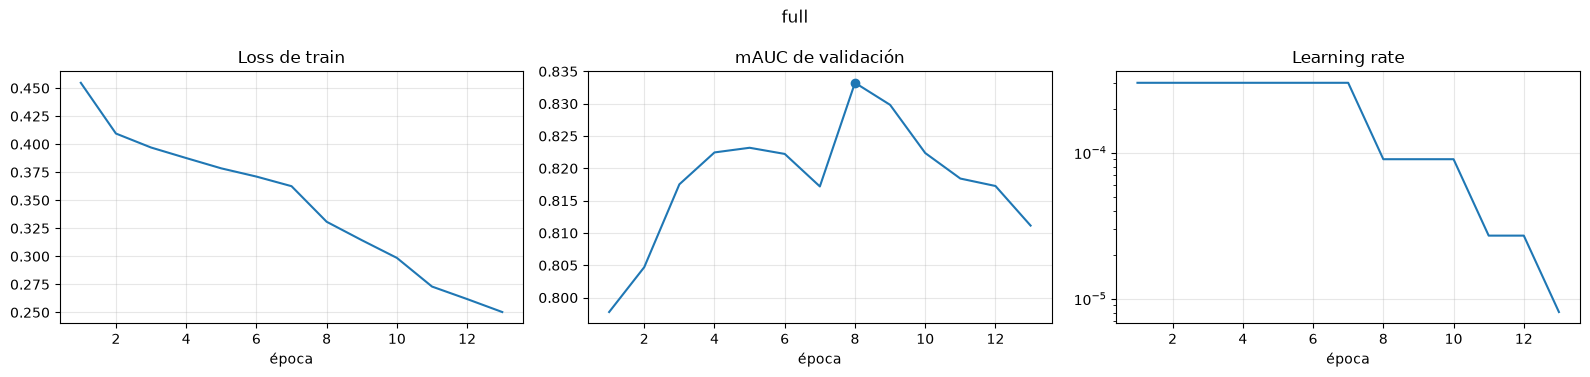

{'test_mAUC': 0.8509021997451782,
 'aucs': tensor([0.7886, 0.8123, 0.9129, 0.8821, 0.7229, 0.8583, 0.7769, 0.8029, 0.8849,
         0.8061, 0.9151, 0.9190, 0.8321, 0.8235, 0.9637]),
 'nf_auc': None,
 'P_test': tensor([[1.8937e-01, 1.3121e-02, 3.9565e-02,  ..., 5.3862e-01, 3.2961e-01,
          9.7616e-05],
         [3.7628e-01, 1.3121e-02, 3.9344e-01,  ..., 1.7148e-01, 2.3231e-01,
          1.1323e-04],
         [4.1123e-01, 7.3174e-03, 3.3047e-01,  ..., 3.8688e-01, 4.5817e-01,
          1.1960e-04],
         ...,
         [7.5187e-03, 1.6357e-03, 1.2241e-02,  ..., 4.2646e-03, 1.9382e-02,
          5.0530e-04],
         [4.9681e-02, 1.1592e-04, 2.6626e-03,  ..., 4.6899e-02, 3.7964e-02,
          2.9596e-04],
         [4.8949e-02, 1.6403e-02, 2.8114e-02,  ..., 9.8079e-02, 3.7609e-02,
          7.4896e-03]])}

In [25]:
resultados_test(full, datos)

### Capas intermedias

**Búsqueda de hiperparámetros (capas intermedias).** Mismo protocolo que en el modelo completo. Aquí también se busca qué bloques se entrenan, además del resto de parámetros.

| Parámetro | Valores probados |
|---|---|
| lr | 1e-4, 3e-4, 1e-3 |
| capas | b2_b3, b3_b4 |
| wd | 1e-2, 5e-2 |
| aug | none, light, medium |
| loss | bce, pw, pw_sqrt |

El mejor resultado fue `lr=1e-3`, `capas=b2_b3`, `wd=5e-2`, `aug=none` y `loss=pw_sqrt`. El lr ganador es el máximo de la rejilla, así que podría existir un valor mejor por encima.

Con estos parámetros entrenamos el modelo definitivo con **todo el conjunto de entrenamiento** (21.563 pacientes, 78.996 imágenes), no con el subconjunto de la búsqueda. Se usa AdamW con precisión mixta (fp16) y un máximo de 20 épocas. El lr sigue un planificador *plateau*: calentamiento lineal durante la primera época y después se multiplica por 0,3 cuando el mAUC de validación no mejora en 1 época. Hay parada temprana tras 5 épocas sin mejorar. En cada época se evalúa el mAUC de validación y se conservan los pesos de la mejor época, que son los que se usan después. El test no se toca hasta la evaluación final. El entrenamiento se detuvo en la época 13, con la mejor en la 8, y alcanzó un mAUC de validación de 0,8177..

In [26]:
ESPACIO_INTER = {
    'lr': [1e-4, 3e-4, 1e-3],
    'capas': ['b2_b3', 'b3_b4'],
    'wd': [1e-2, 5e-2],
    'aug': ['none', 'light', 'medium'],
    'loss': ['bce', 'pw', 'pw_sqrt'],
}
mejores_inter = buscar_hiperparametros(datos, construir_config(capas='b2_b3'), ESPACIO_INTER, nombre='inter')

[1] {'lr': 0.0001, 'capas': 'b2_b3', 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.7796
[2] {'lr': 0.0003, 'capas': 'b2_b3', 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.8030
[3] {'lr': 0.001, 'capas': 'b2_b3', 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.8132
>> mejor lr: 0.001
[4] {'lr': 0.001, 'capas': 'b3_b4', 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.8075
>> mejor capas: b2_b3
[5] {'lr': 0.001, 'capas': 'b2_b3', 'wd': 0.05, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.8147
>> mejor wd: 0.05
[6] {'lr': 0.001, 'capas': 'b2_b3', 'wd': 0.05, 'aug': 'light', 'loss': 'bce'} -> val mAUC 0.8134
[7] {'lr': 0.001, 'capas': 'b2_b3', 'wd': 0.05, 'aug': 'medium', 'loss': 'bce'} -> val mAUC 0.8112
>> mejor aug: none
[8] {'lr': 0.001, 'capas': 'b2_b3', 'wd': 0.05, 'aug': 'none', 'loss': 'pw'} -> val mAUC 0.8014
[9] {'lr': 0.001, 'capas': 'b2_b3', 'wd': 0.05, 'aug': 'none', 'loss': 'pw_sqrt'} -> val mAUC 0.8231
>> mejor loss: pw_sqrt

Resultados de la 

In [27]:
inter = entrenar(datos, mejores_inter, nombre='inter')

ep  0 | loss train 0.4506 | val mAUC 0.7751 | lr 1.0e-03
ep  1 | loss train 0.4209 | val mAUC 0.8055 | lr 1.0e-03
ep  2 | loss train 0.4077 | val mAUC 0.8097 | lr 1.0e-03
ep  3 | loss train 0.3979 | val mAUC 0.8157 | lr 1.0e-03
ep  4 | loss train 0.3891 | val mAUC 0.8108 | lr 1.0e-03
ep  5 | loss train 0.3813 | val mAUC 0.8163 | lr 1.0e-03
ep  6 | loss train 0.3730 | val mAUC 0.7930 | lr 1.0e-03
ep  7 | loss train 0.3665 | val mAUC 0.8177 | lr 1.0e-03
ep  8 | loss train 0.3591 | val mAUC 0.8137 | lr 1.0e-03
ep  9 | loss train 0.3534 | val mAUC 0.8117 | lr 1.0e-03
ep 10 | loss train 0.3038 | val mAUC 0.8126 | lr 3.0e-04
ep 11 | loss train 0.2710 | val mAUC 0.8105 | lr 3.0e-04
ep 12 | loss train 0.2267 | val mAUC 0.8003 | lr 9.0e-05
parada temprana: 5 épocas sin mejorar
inter: 13 épocas, mejor la 8, val mAUC 0.8177


inter: val mAUC 0.8177 | test mAUC 0.8322
┌──────────────────────┬────────────┐
│        Clase         │ AUROC test │
├──────────────────────┼────────────┤
│      No Finding      │   0.7752   │
│     Atelectasis      │   0.7946   │
│     Cardiomegaly     │   0.9045   │
│       Effusion       │   0.8764   │
│     Infiltration     │   0.7064   │
│         Mass         │   0.8294   │
│        Nodule        │   0.7412   │
│      Pneumonia       │   0.7915   │
│     Pneumothorax     │   0.8652   │
│    Consolidation     │   0.7895   │
│        Edema         │   0.9131   │
│      Emphysema       │   0.9015   │
│       Fibrosis       │   0.8149   │
│  Pleural Thickening  │   0.7967   │
│        Hernia        │   0.9253   │
├──────────────────────┼────────────┤
│ mAUC (14 patologías) │   0.8322   │
└──────────────────────┴────────────┘


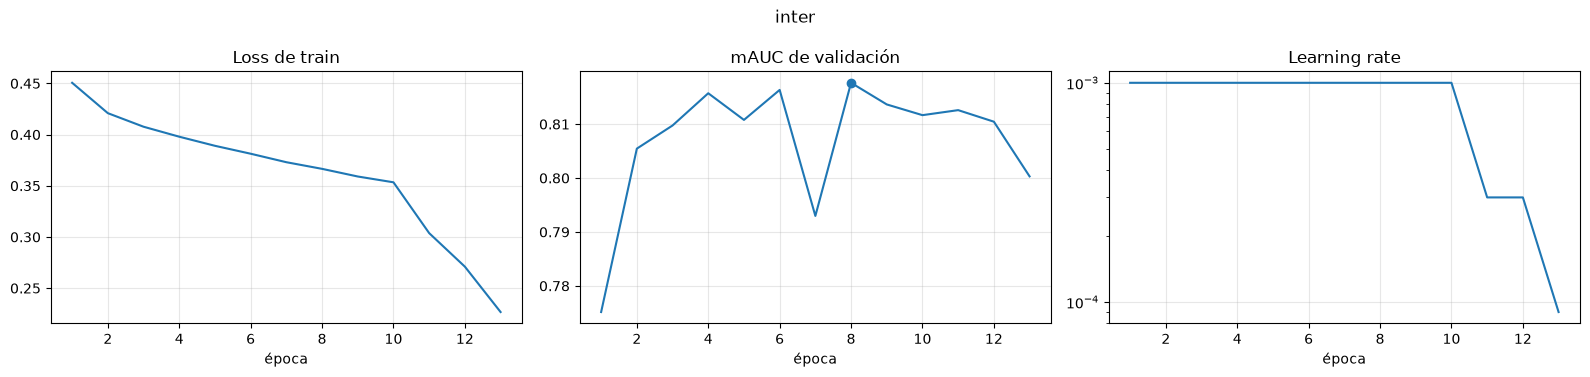

{'test_mAUC': 0.8321500420570374,
 'aucs': tensor([0.7752, 0.7946, 0.9045, 0.8764, 0.7064, 0.8294, 0.7412, 0.7915, 0.8652,
         0.7895, 0.9131, 0.9015, 0.8149, 0.7967, 0.9253]),
 'nf_auc': None,
 'P_test': tensor([[2.4328e-01, 1.4010e-02, 1.2085e-01,  ..., 8.4273e-01, 5.2412e-01,
          1.7007e-03],
         [4.2549e-01, 7.4097e-02, 3.3253e-01,  ..., 2.5777e-01, 2.2085e-01,
          1.4214e-03],
         [3.0487e-01, 2.7273e-02, 4.1253e-01,  ..., 4.5405e-01, 3.6534e-01,
          4.7101e-04],
         ...,
         [1.5015e-02, 2.9810e-03, 6.4381e-03,  ..., 1.9419e-02, 7.3297e-02,
          3.3860e-07],
         [1.1260e-01, 4.9823e-03, 1.8942e-02,  ..., 9.9645e-02, 7.5721e-02,
          3.6976e-06],
         [5.3010e-02, 1.1798e-01, 1.5191e-01,  ..., 1.2475e-01, 1.1028e-01,
          1.3631e-05]])}

In [28]:
resultados_test(inter, datos)

### Cabecera

**Búsqueda de hiperparámetros (cabecera).** Mismo protocolo que en las otras dos. Solo se entrena el clasificador, así que se prueban lr más altos y otro rango de weight decay.

| Parámetro | Valores probados |
|---|---|
| lr | 3e-4, 1e-3, 3e-3, 1e-2 |
| wd | 1e-4, 1e-2 |
| aug | none, light, medium |
| loss | bce, pw, pw_sqrt |

El mejor resultado fue `lr=3e-3`, `wd=1e-2`, `aug=none` y `loss=pw_sqrt`.

Con estos parámetros entrenamos el modelo definitivo con **todo el conjunto de entrenamiento** (21.563 pacientes, 78.996 imágenes), no con el subconjunto de la búsqueda. Se usa AdamW con precisión mixta (fp16) y un máximo de 20 épocas. El lr sigue un planificador *plateau*: calentamiento lineal durante la primera época y después se multiplica por 0,3 cuando el mAUC de validación no mejora en 1 época. Hay parada temprana tras 5 épocas sin mejorar. En cada época se evalúa el mAUC de validación y se conservan los pesos de la mejor época, que son los que se usan después. El test no se toca hasta la evaluación final. El entrenamiento agotó las 20 épocas sin activar la parada temprana, con la mejor en la 19, y alcanzó un mAUC de validación de 0,7306.

In [29]:
ESPACIO_HEAD = {
    'lr': [3e-4, 1e-3, 3e-3, 1e-2],
    'wd': [1e-4, 1e-2],
    'aug': ['none', 'light', 'medium'],
    'loss': ['bce', 'pw', 'pw_sqrt'],
}
mejores_head = buscar_hiperparametros(datos, construir_config(capas='cabecera'), ESPACIO_HEAD, nombre='head')

[1] {'lr': 0.0003, 'wd': 0.0001, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.6206
[2] {'lr': 0.001, 'wd': 0.0001, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.6912
[3] {'lr': 0.003, 'wd': 0.0001, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.7209
[4] {'lr': 0.01, 'wd': 0.0001, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.7135
>> mejor lr: 0.003
[5] {'lr': 0.003, 'wd': 0.01, 'aug': 'none', 'loss': 'bce'} -> val mAUC 0.7210
>> mejor wd: 0.01
[6] {'lr': 0.003, 'wd': 0.01, 'aug': 'light', 'loss': 'bce'} -> val mAUC 0.7152
[7] {'lr': 0.003, 'wd': 0.01, 'aug': 'medium', 'loss': 'bce'} -> val mAUC 0.7118
>> mejor aug: none
[8] {'lr': 0.003, 'wd': 0.01, 'aug': 'none', 'loss': 'pw'} -> val mAUC 0.7229
[9] {'lr': 0.003, 'wd': 0.01, 'aug': 'none', 'loss': 'pw_sqrt'} -> val mAUC 0.7237
>> mejor loss: pw_sqrt

Resultados de la búsqueda (validación):
┌───┬────────┬────────┬────────┬─────────┬──────────┬─────────────┐
│ # │   lr   │   wd   │  aug   │   loss  │ val_mAUC │ mejor_epoca │
├───┼────────┼─────

In [30]:
head = entrenar(datos, mejores_head, nombre='head')

ep  0 | loss train 0.4983 | val mAUC 0.7175 | lr 3.0e-03
ep  1 | loss train 0.4951 | val mAUC 0.7186 | lr 3.0e-03
ep  2 | loss train 0.4925 | val mAUC 0.7210 | lr 3.0e-03
ep  3 | loss train 0.4890 | val mAUC 0.7197 | lr 3.0e-03
ep  4 | loss train 0.4878 | val mAUC 0.7225 | lr 3.0e-03
ep  5 | loss train 0.4886 | val mAUC 0.7203 | lr 3.0e-03
ep  6 | loss train 0.4872 | val mAUC 0.7208 | lr 3.0e-03
ep  7 | loss train 0.4509 | val mAUC 0.7269 | lr 9.0e-04
ep  8 | loss train 0.4496 | val mAUC 0.7262 | lr 9.0e-04
ep  9 | loss train 0.4498 | val mAUC 0.7271 | lr 9.0e-04
ep 10 | loss train 0.4497 | val mAUC 0.7290 | lr 9.0e-04
ep 11 | loss train 0.4498 | val mAUC 0.7270 | lr 9.0e-04
ep 12 | loss train 0.4497 | val mAUC 0.7290 | lr 9.0e-04
ep 13 | loss train 0.4380 | val mAUC 0.7289 | lr 2.7e-04
ep 14 | loss train 0.4376 | val mAUC 0.7295 | lr 2.7e-04
ep 15 | loss train 0.4374 | val mAUC 0.7300 | lr 2.7e-04
ep 16 | loss train 0.4372 | val mAUC 0.7299 | lr 2.7e-04
ep 17 | loss train 0.4376 | val

head: val mAUC 0.7306 | test mAUC 0.7346
┌──────────────────────┬────────────┐
│        Clase         │ AUROC test │
├──────────────────────┼────────────┤
│      No Finding      │   0.7195   │
│     Atelectasis      │   0.7167   │
│     Cardiomegaly     │   0.7559   │
│       Effusion       │   0.7817   │
│     Infiltration     │   0.6632   │
│         Mass         │   0.6937   │
│        Nodule        │   0.6335   │
│      Pneumonia       │   0.6708   │
│     Pneumothorax     │   0.7776   │
│    Consolidation     │   0.7326   │
│        Edema         │   0.8554   │
│      Emphysema       │   0.7939   │
│       Fibrosis       │   0.7269   │
│  Pleural Thickening  │   0.7191   │
│        Hernia        │   0.7636   │
├──────────────────────┼────────────┤
│ mAUC (14 patologías) │   0.7346   │
└──────────────────────┴────────────┘


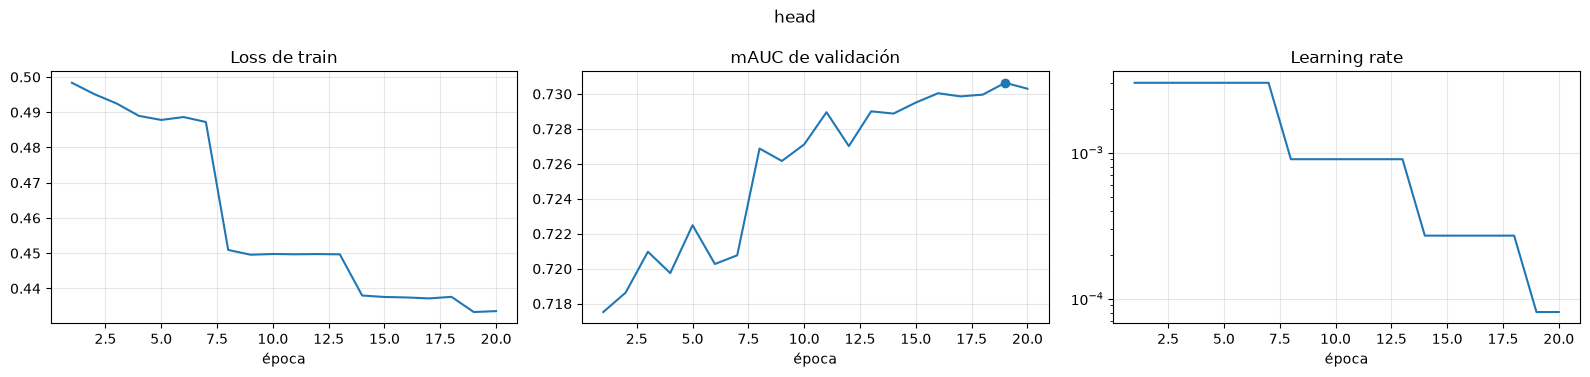

{'test_mAUC': 0.7346105575561523,
 'aucs': tensor([0.7195, 0.7167, 0.7559, 0.7817, 0.6632, 0.6937, 0.6335, 0.6708, 0.7776,
         0.7326, 0.8554, 0.7939, 0.7269, 0.7191, 0.7636]),
 'nf_auc': None,
 'P_test': tensor([[0.2144, 0.3567, 0.1041,  ..., 0.3636, 0.1338, 0.3550],
         [0.1985, 0.1254, 0.2116,  ..., 0.0484, 0.0730, 0.0099],
         [0.4586, 0.1327, 0.3845,  ..., 0.2259, 0.3909, 0.5281],
         ...,
         [0.0846, 0.0548, 0.0600,  ..., 0.0548, 0.1383, 0.0040],
         [0.1469, 0.0039, 0.1045,  ..., 0.0667, 0.2276, 0.0014],
         [0.0545, 0.1552, 0.0276,  ..., 0.0721, 0.0920, 0.0104]])}

In [31]:
resultados_test(head, datos)

### Comparativa

Como podemos observar, hay una gran diferencia cuando se re-entrena el modelo completo o las capas intermedias respecto a cuando se re-entrena solo la cabecera.

Aún así, como podemos comprobar en la gráfica, la desviación típica de los resultados nos indica que es singificativa la mejora del modelo completo respecto al de capas intermedias. Esto se debe a que al estar el modelo completo fuera del "alcance" de la desviación típica del de capas intermedias ya no está en el margen de error / ruido.

┌───────────────────┬────────────┬────────────────────────┬────────────────┬──────────┬───────────┬──────────────────┬────────────────────┬────────────────────┐
│       Modelo      │ Nº modelos │ Parámetros entrenables │ Épocas (mejor) │ val mAUC │ test mAUC │   IC 95 % test   │ Δ test vs Completo │     IC 95 % Δ      │
├───────────────────┼────────────┼────────────────────────┼────────────────┼──────────┼───────────┼──────────────────┼────────────────────┼────────────────────┤
│      Completo     │     1      │       6,962,959        │     13 (8)     │  0.8332  │   0.8509  │ [0.8433, 0.8562] │         -          │         -          │
│ Capas intermedias │     1      │       4,431,247        │     13 (8)     │  0.8177  │   0.8322  │ [0.8246, 0.8390] │      -0.0188       │ [-0.0231, -0.0141] │
│      Cabecera     │     1      │         15,375         │    20 (19)     │  0.7306  │   0.7346  │ [0.7237, 0.7456] │      -0.1163       │ [-0.1248, -0.1062] │
└───────────────────┴────────────┴

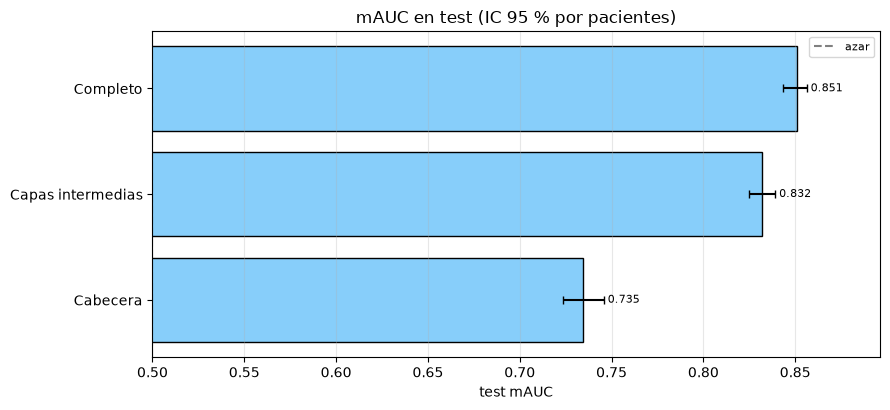

{'Completo': {'val_mAUC': 0.8332315683364868,
  'test_mAUC': 0.8509021997451782,
  'ic95': (0.8433357149362564, 0.856167984008789),
  'delta': 0.0,
  'ic95_delta': (0.0, 0.0),
  'aucs': tensor([0.8123, 0.9129, 0.8821, 0.7229, 0.8583, 0.7769, 0.8029, 0.8849, 0.8061,
          0.9151, 0.9190, 0.8321, 0.8235, 0.9637])},
 'Capas intermedias': {'val_mAUC': 0.8176659345626831,
  'test_mAUC': 0.8321500420570374,
  'ic95': (0.8245829567313194, 0.8389836192131043),
  'delta': -0.01875215768814087,
  'ic95_delta': (-0.023129068315029144, -0.014110039174556731),
  'aucs': tensor([0.7946, 0.9045, 0.8764, 0.7064, 0.8294, 0.7412, 0.7915, 0.8652, 0.7895,
          0.9131, 0.9015, 0.8149, 0.7967, 0.9253])},
 'Cabecera': {'val_mAUC': 0.7306385040283203,
  'test_mAUC': 0.7346105575561523,
  'ic95': (0.7237373009324074, 0.7456440389156341),
  'delta': -0.11629164218902588,
  'ic95_delta': (-0.12476314604282379, -0.10617166310548783),
  'aucs': tensor([0.7167, 0.7559, 0.7817, 0.6632, 0.6937, 0.6335, 0.670

In [32]:
comparar(datos, {'Completo': full, 'Capas intermedias': inter, 'Cabecera': head})

## Experimento: *No Finding* derivado

Para este apartado se han utilizado los mejores parámetros encontrados en la fase anterior para cada uno de los tres modelos (completo, capas intermedias y cabecera). Esto se hace para aislar la comparativa exclusivamete al hecho de utilizar 15 clases incluyendo *No Findings* o utilizar 14 y deducir *No Finding* a partir del resto.

### Completo

In [33]:
full_nf = entrenar(datos, construir_config(mejores_full, no_finding='derivado'), nombre='full_nf')

ep  0 | loss train 0.4477 | val mAUC 0.7852 | lr 3.0e-04
ep  1 | loss train 0.3991 | val mAUC 0.8130 | lr 3.0e-04
ep  2 | loss train 0.3854 | val mAUC 0.8189 | lr 3.0e-04
ep  3 | loss train 0.3770 | val mAUC 0.8115 | lr 3.0e-04
ep  4 | loss train 0.3689 | val mAUC 0.8306 | lr 3.0e-04
ep  5 | loss train 0.3600 | val mAUC 0.8278 | lr 3.0e-04
ep  6 | loss train 0.3520 | val mAUC 0.8272 | lr 3.0e-04
ep  7 | loss train 0.3200 | val mAUC 0.8336 | lr 9.0e-05
ep  8 | loss train 0.3026 | val mAUC 0.8312 | lr 9.0e-05
ep  9 | loss train 0.2880 | val mAUC 0.8266 | lr 9.0e-05
ep 10 | loss train 0.2609 | val mAUC 0.8189 | lr 2.7e-05
ep 11 | loss train 0.2502 | val mAUC 0.8134 | lr 2.7e-05
ep 12 | loss train 0.2385 | val mAUC 0.8136 | lr 8.1e-06
parada temprana: 5 épocas sin mejorar
full_nf: 13 épocas, mejor la 8, val mAUC 0.8336


### Capas intermedias

In [34]:
inter_nf = entrenar(datos, construir_config(mejores_inter, no_finding='derivado'), nombre='inter_nf')

ep  0 | loss train 0.4420 | val mAUC 0.7824 | lr 1.0e-03
ep  1 | loss train 0.4099 | val mAUC 0.7954 | lr 1.0e-03
ep  2 | loss train 0.3963 | val mAUC 0.8114 | lr 1.0e-03
ep  3 | loss train 0.3879 | val mAUC 0.7991 | lr 1.0e-03
ep  4 | loss train 0.3783 | val mAUC 0.8201 | lr 1.0e-03
ep  5 | loss train 0.3710 | val mAUC 0.8199 | lr 1.0e-03
ep  6 | loss train 0.3622 | val mAUC 0.8131 | lr 1.0e-03
ep  7 | loss train 0.3209 | val mAUC 0.8255 | lr 3.0e-04
ep  8 | loss train 0.2942 | val mAUC 0.8194 | lr 3.0e-04
ep  9 | loss train 0.2666 | val mAUC 0.8149 | lr 3.0e-04
ep 10 | loss train 0.2199 | val mAUC 0.8087 | lr 9.0e-05
ep 11 | loss train 0.1993 | val mAUC 0.8030 | lr 9.0e-05
ep 12 | loss train 0.1772 | val mAUC 0.8007 | lr 2.7e-05
parada temprana: 5 épocas sin mejorar
inter_nf: 13 épocas, mejor la 8, val mAUC 0.8255


### Cabecera

In [35]:
head_nf = entrenar(datos, construir_config(mejores_head, no_finding='derivado'), nombre='head_nf')

ep  0 | loss train 0.4900 | val mAUC 0.7161 | lr 3.0e-03
ep  1 | loss train 0.4879 | val mAUC 0.7218 | lr 3.0e-03
ep  2 | loss train 0.4819 | val mAUC 0.7234 | lr 3.0e-03
ep  3 | loss train 0.4831 | val mAUC 0.7193 | lr 3.0e-03
ep  4 | loss train 0.4797 | val mAUC 0.7233 | lr 3.0e-03
ep  5 | loss train 0.4422 | val mAUC 0.7258 | lr 9.0e-04
ep  6 | loss train 0.4400 | val mAUC 0.7263 | lr 9.0e-04
ep  7 | loss train 0.4404 | val mAUC 0.7266 | lr 9.0e-04
ep  8 | loss train 0.4399 | val mAUC 0.7286 | lr 9.0e-04
ep  9 | loss train 0.4390 | val mAUC 0.7282 | lr 9.0e-04
ep 10 | loss train 0.4395 | val mAUC 0.7276 | lr 9.0e-04
ep 11 | loss train 0.4270 | val mAUC 0.7283 | lr 2.7e-04
ep 12 | loss train 0.4269 | val mAUC 0.7281 | lr 2.7e-04
ep 13 | loss train 0.4229 | val mAUC 0.7292 | lr 8.1e-05
ep 14 | loss train 0.4228 | val mAUC 0.7302 | lr 8.1e-05
ep 15 | loss train 0.4226 | val mAUC 0.7288 | lr 8.1e-05
ep 16 | loss train 0.4231 | val mAUC 0.7299 | lr 8.1e-05
ep 17 | loss train 0.4216 | val

### Comparativa

**Cómo leer la tabla.** Cada fila es una estrategia de fine-tuning y se comparan dos variantes: «con NF», con *No Finding* como una clase más (15 salidas), y «sin NF», con *No Finding* derivado (14 salidas). Para que sean comparables, el **mAUC es siempre la media del AUROC de las 14 patologías**, también en el modelo de 15 salidas. Se informa en validación (la que se usa para elegir la época y los hiperparámetros) y en test (la evaluación final, que no interviene en ninguna decisión).

**Cómo se calcula *No Finding* derivado.** El modelo de 14 salidas no predice *No Finding*. Se deduce de que ninguna patología esté presente, a partir de las probabilidades *p_i* de las 14 patologías, con dos puntuaciones:
- **prod(1 − p)**: probabilidad de que todas las patologías estén ausentes.
- **1 − max(p)**: se confía en la patología más probable, y si incluso esa es improbable, el estudio se considera normal.

Se calcula el AUROC de *No Finding* con ambas, y se compara con el AUROC de la salida propia del modelo de 15 salidas («clase»).

┌───────────────────┬───────────────────┬───────────────────┬────────────────────┬────────────────────┬──────────────────┬─────────────────┬──────────────────┐
│     Estrategia    │ val mAUC (con NF) │ val mAUC (sin NF) │ test mAUC (con NF) │ test mAUC (sin NF) │ AUROC NF (clase) │ AUROC NF (prod) │ AUROC NF (1-max) │
├───────────────────┼───────────────────┼───────────────────┼────────────────────┼────────────────────┼──────────────────┼─────────────────┼──────────────────┤
│      Completo     │       0.8332      │       0.8336      │       0.8509       │       0.8451       │      0.7886      │      0.7830     │      0.7686      │
│ Capas intermedias │       0.8177      │       0.8255      │       0.8322       │       0.8380       │      0.7752      │      0.7751     │      0.7576      │
│      Cabecera     │       0.7306      │       0.7302      │       0.7346       │       0.7336       │      0.7195      │      0.7165     │      0.7027      │
└───────────────────┴───────────────────

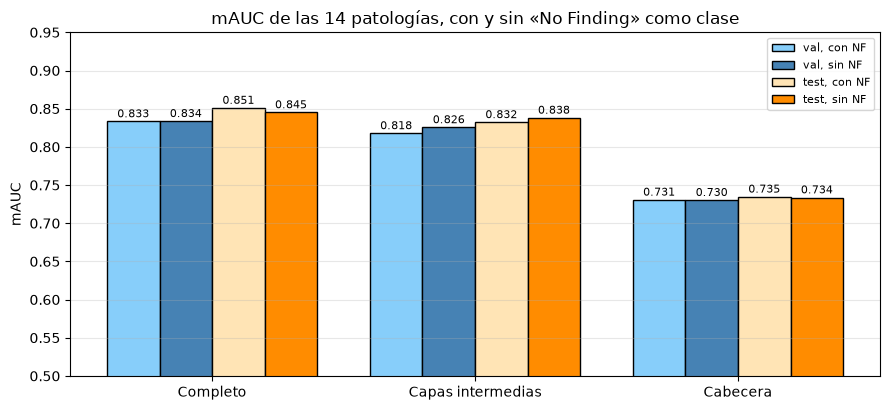

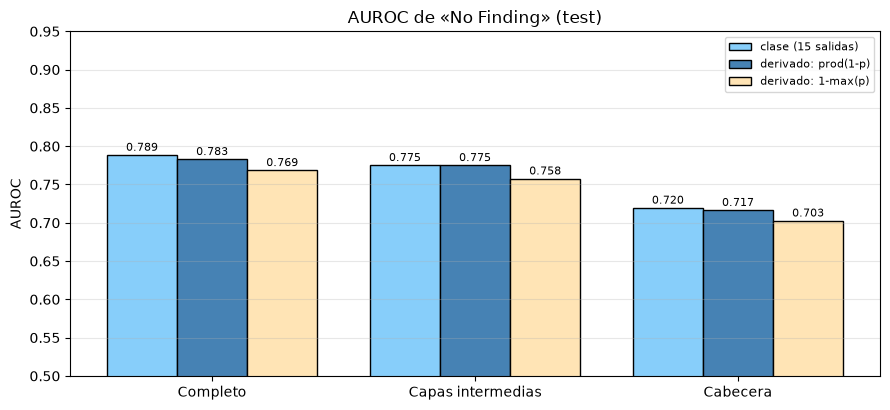

In [ ]:
comparar_no_finding(datos, {
    'Completo':          (full,  full_nf),
    'Capas intermedias': (inter, inter_nf),
    'Cabecera':          (head,  head_nf),
})

## Promedio de modelos

**Qué se hace.** Se combinan varios modelos ya entrenados promediando sus probabilidades de salida para cada patología (promedio simple, sin pesos). No se entrena nada nuevo y nada se ajusta con validación ni con test.

**En qué consiste y por qué puede ayudar.** Cada modelo se equivoca de forma distinta, porque difiere en las capas entrenadas, en los hiperparámetros o en cómo se define «No Finding». Al promediar, **los errores que no comparten se compensan** y **la predicción es más estable**.

┌───────────────────────────────────────┬────────────┬────────────────────────┬────────────────┬──────────┬───────────┬──────────────────┬────────────────────┬────────────────────┐
│                 Modelo                │ Nº modelos │ Parámetros entrenables │ Épocas (mejor) │ val mAUC │ test mAUC │   IC 95 % test   │ Δ test vs completo │     IC 95 % Δ      │
├───────────────────────────────────────┼────────────┼────────────────────────┼────────────────┼──────────┼───────────┼──────────────────┼────────────────────┼────────────────────┤
│                completo               │     1      │       6,962,959        │     13 (8)     │  0.8332  │   0.8509  │ [0.8433, 0.8562] │         -          │         -          │
│           capas intermedias           │     1      │       4,431,247        │     13 (8)     │  0.8177  │   0.8322  │ [0.8246, 0.8390] │      -0.0188       │ [-0.0231, -0.0141] │
│         completo + intermedias        │     2      │           -            │       -        

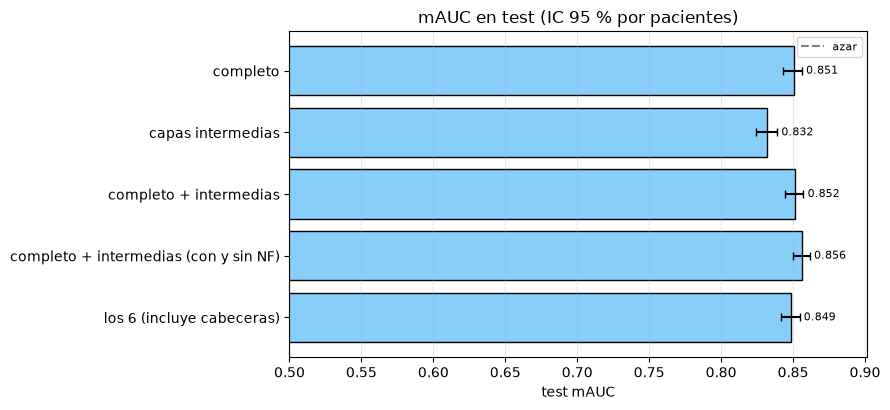

{'completo': {'val_mAUC': 0.8332315683364868,
  'test_mAUC': 0.8509021997451782,
  'ic95': (0.8433357149362564, 0.856167984008789),
  'delta': 0.0,
  'ic95_delta': (0.0, 0.0),
  'aucs': tensor([0.8123, 0.9129, 0.8821, 0.7229, 0.8583, 0.7769, 0.8029, 0.8849, 0.8061,
          0.9151, 0.9190, 0.8321, 0.8235, 0.9637])},
 'capas intermedias': {'val_mAUC': 0.8176659345626831,
  'test_mAUC': 0.8321500420570374,
  'ic95': (0.8245829567313194, 0.8389836192131043),
  'delta': -0.01875215768814087,
  'ic95_delta': (-0.023129068315029144, -0.014110039174556731),
  'aucs': tensor([0.7946, 0.9045, 0.8764, 0.7064, 0.8294, 0.7412, 0.7915, 0.8652, 0.7895,
          0.9131, 0.9015, 0.8149, 0.7967, 0.9253])},
 'completo + intermedias': {'val_mAUC': 0.8372377753257751,
  'test_mAUC': 0.8515329360961914,
  'ic95': (0.8447293594479561, 0.8572401538491249),
  'delta': 0.0006307363510131836,
  'ic95_delta': (-0.0011799871921539305, 0.002547295391559601),
  'aucs': tensor([0.8122, 0.9156, 0.8853, 0.7219, 0.85

In [37]:
comparar(datos, {
    'completo': full,
    'capas intermedias': inter,
    'completo + intermedias': [full, inter],
    'completo + intermedias (con y sin NF)': [full, inter, full_nf, inter_nf],
    'los 6 (incluye cabeceras)': [full, inter, head, full_nf, inter_nf, head_nf],
}, referencia='completo', por_clase=True)

## Otros experimentos

Se parte del mejor modelo (**completo**, con aumento `light`, planificador *plateau* y parada temprana) y se cambia **una cosa cada vez** para ver si el entrenamiento se puede mejorar sin tocar la arquitectura ni la búsqueda de hiperparámetros.

### Planificador: calendario fijo

En lugar de bajar el lr cuando la validación se estanca, se usa un coseno fijo de 15 épocas (calentamiento de 1 época y bajada suave hasta lr/100), sin parada temprana. Puede ayudar porque la reducción gradual del lr afina mejor al final. Puede perjudicar porque ya no se adapta al comportamiento real de la validación y puede sobre-entrenar al final.

In [38]:
# El modelo completo de arriba usa el planificador por plateau con parada temprana; aquí, el calendario fijo en coseno
full_coseno = entrenar(datos, construir_config(mejores_full, scheduler='coseno', epocas=15, paciencia=None), nombre='full_coseno')

ep  0 | loss train 0.5509 | val mAUC 0.7149 | lr 3.0e-06
ep  1 | loss train 0.4290 | val mAUC 0.7957 | lr 3.0e-04
ep  2 | loss train 0.4036 | val mAUC 0.8122 | lr 2.9e-04
ep  3 | loss train 0.3913 | val mAUC 0.8231 | lr 2.7e-04
ep  4 | loss train 0.3802 | val mAUC 0.8220 | lr 2.5e-04
ep  5 | loss train 0.3679 | val mAUC 0.8255 | lr 2.3e-04
ep  6 | loss train 0.3545 | val mAUC 0.8206 | lr 2.0e-04
ep  7 | loss train 0.3395 | val mAUC 0.8274 | lr 1.7e-04
ep  8 | loss train 0.3198 | val mAUC 0.8256 | lr 1.4e-04
ep  9 | loss train 0.2963 | val mAUC 0.8185 | lr 1.1e-04
ep 10 | loss train 0.2707 | val mAUC 0.8130 | lr 7.7e-05
ep 11 | loss train 0.2442 | val mAUC 0.8075 | lr 5.2e-05
ep 12 | loss train 0.2229 | val mAUC 0.7956 | lr 3.1e-05
ep 13 | loss train 0.2076 | val mAUC 0.7934 | lr 1.6e-05
ep 14 | loss train 0.1987 | val mAUC 0.7915 | lr 6.2e-06
full_coseno: 15 épocas, mejor la 8, val mAUC 0.8274


### Aumento de datos fuerte

Se cambia `light` por `strong`: **recorte aleatorio (80–100 % del área), rotación ±10°, traslación 5 % y brillo y contraste ±30 %**. Puede ayudar porque regulariza y reduce el sobreajuste (la loss de train baja mucho más que la de validación). Puede perjudicar porque las perturbaciones fuertes alteran demasiado como para aprender y alejan el train de las imágenes de test, que no se alteran, y el modelo converge más despacio.


In [39]:
full_fuerte = entrenar(datos, construir_config(mejores_full, aug='strong'), nombre='full_fuerte')

ep  0 | loss train 0.4611 | val mAUC 0.7926 | lr 3.0e-04
ep  1 | loss train 0.4181 | val mAUC 0.8011 | lr 3.0e-04
ep  2 | loss train 0.4058 | val mAUC 0.8083 | lr 3.0e-04
ep  3 | loss train 0.3974 | val mAUC 0.8205 | lr 3.0e-04
ep  4 | loss train 0.3898 | val mAUC 0.8220 | lr 3.0e-04
ep  5 | loss train 0.3831 | val mAUC 0.8166 | lr 3.0e-04
ep  6 | loss train 0.3763 | val mAUC 0.8248 | lr 3.0e-04
ep  7 | loss train 0.3714 | val mAUC 0.8293 | lr 3.0e-04
ep  8 | loss train 0.3647 | val mAUC 0.8294 | lr 3.0e-04
ep  9 | loss train 0.3593 | val mAUC 0.8295 | lr 3.0e-04
ep 10 | loss train 0.3536 | val mAUC 0.8294 | lr 3.0e-04
ep 11 | loss train 0.3468 | val mAUC 0.8266 | lr 3.0e-04
ep 12 | loss train 0.3165 | val mAUC 0.8273 | lr 9.0e-05
ep 13 | loss train 0.3017 | val mAUC 0.8240 | lr 9.0e-05
ep 14 | loss train 0.2824 | val mAUC 0.8209 | lr 2.7e-05
parada temprana: 5 épocas sin mejorar
full_fuerte: 15 épocas, mejor la 10, val mAUC 0.8295


### Inicialización desde la cabecera (LP-FT)

Se parte del clasificador ya entrenado con la red congelada (*linear probing*) y después se ajusta toda la red (*fine-tuning*), con aumento fuerte. Puede ayudar porque una cabecera aleatoria al inicio genera gradientes grandes que distorsionan las características pre-entrenadas. Con una cabecera ya razonable, el ajuste empieza más estable. Puede no ayudar si la cabecera es mala (su mAUC es ≈0,73) o si el ajuste completo la corrige rápido de todos modos.

In [40]:
full_lpft = entrenar(datos, construir_config(mejores_full, aug='strong', init='head'), nombre='full_lpft')

ep  0 | loss train 0.4495 | val mAUC 0.7965 | lr 3.0e-04
ep  1 | loss train 0.4199 | val mAUC 0.7969 | lr 3.0e-04
ep  2 | loss train 0.4095 | val mAUC 0.8047 | lr 3.0e-04
ep  3 | loss train 0.4010 | val mAUC 0.8147 | lr 3.0e-04
ep  4 | loss train 0.3937 | val mAUC 0.8110 | lr 3.0e-04
ep  5 | loss train 0.3865 | val mAUC 0.8233 | lr 3.0e-04
ep  6 | loss train 0.3797 | val mAUC 0.8176 | lr 3.0e-04
ep  7 | loss train 0.3745 | val mAUC 0.8286 | lr 3.0e-04
ep  8 | loss train 0.3680 | val mAUC 0.8283 | lr 3.0e-04
ep  9 | loss train 0.3622 | val mAUC 0.8295 | lr 3.0e-04
ep 10 | loss train 0.3565 | val mAUC 0.8222 | lr 3.0e-04
ep 11 | loss train 0.3502 | val mAUC 0.8288 | lr 3.0e-04
ep 12 | loss train 0.3184 | val mAUC 0.8260 | lr 9.0e-05
ep 13 | loss train 0.3034 | val mAUC 0.8209 | lr 9.0e-05
ep 14 | loss train 0.2825 | val mAUC 0.8188 | lr 2.7e-05
parada temprana: 5 épocas sin mejorar
full_lpft: 15 épocas, mejor la 10, val mAUC 0.8295


### Reflejo horizontal

Se añade volteo horizontal al aumento `strong`. Duplica la variedad de imágenes y suele ser una de las regularizaciones más eficaces. Pero en tórax tiene un coste: **el corazón queda a la derecha**, algo *anatómicamente poco realista* (dextrocardia). **Puede afectar a patologías que dependen de la posición**, como la cardiomegalia.

In [41]:
full_flip = entrenar(datos, construir_config(mejores_full, aug='strong_flip'), nombre='full_flip')

ep  0 | loss train 0.4642 | val mAUC 0.7868 | lr 3.0e-04
ep  1 | loss train 0.4219 | val mAUC 0.8010 | lr 3.0e-04
ep  2 | loss train 0.4106 | val mAUC 0.8047 | lr 3.0e-04
ep  3 | loss train 0.4019 | val mAUC 0.8191 | lr 3.0e-04
ep  4 | loss train 0.3959 | val mAUC 0.8182 | lr 3.0e-04
ep  5 | loss train 0.3907 | val mAUC 0.8238 | lr 3.0e-04
ep  6 | loss train 0.3854 | val mAUC 0.8192 | lr 3.0e-04
ep  7 | loss train 0.3815 | val mAUC 0.8308 | lr 3.0e-04
ep  8 | loss train 0.3769 | val mAUC 0.8247 | lr 3.0e-04
ep  9 | loss train 0.3729 | val mAUC 0.8260 | lr 3.0e-04
ep 10 | loss train 0.3524 | val mAUC 0.8353 | lr 9.0e-05
ep 11 | loss train 0.3437 | val mAUC 0.8346 | lr 9.0e-05
ep 12 | loss train 0.3373 | val mAUC 0.8314 | lr 9.0e-05
ep 13 | loss train 0.3261 | val mAUC 0.8323 | lr 2.7e-05
ep 14 | loss train 0.3227 | val mAUC 0.8327 | lr 2.7e-05
ep 15 | loss train 0.3174 | val mAUC 0.8311 | lr 8.1e-06
parada temprana: 5 épocas sin mejorar
full_flip: 16 épocas, mejor la 11, val mAUC 0.8353

### Comparación

**Conclusión.** Ninguna de las variantes de entrenamiento mejora al modelo completo de referencia (plateau + parada temprana, test mAUC **0,8509**). Todas las diferencias en test son negativas:

| Variante | test mAUC  | ¿Distinguible del ruido? |
|---|---|---|
| Calendario fijo (coseno) | 0,8444 | Sí, peor |
| Aumento fuerte | 0,8423 | Sí, peor |
| Aumento fuerte + LP-FT | 0,8409 | Sí, peor |
| Aumento fuerte + reflejo | 0,8499 | No  |


┌──────────────────────────────────────┬────────────┬────────────────────────┬────────────────┬──────────┬───────────┬──────────────────┬────────────────────────────────────────────────┬────────────────────┐
│                Modelo                │ Nº modelos │ Parámetros entrenables │ Épocas (mejor) │ val mAUC │ test mAUC │   IC 95 % test   │ Δ test vs completo (plateau + parada temprana) │     IC 95 % Δ      │
├──────────────────────────────────────┼────────────┼────────────────────────┼────────────────┼──────────┼───────────┼──────────────────┼────────────────────────────────────────────────┼────────────────────┤
│ completo (plateau + parada temprana) │     1      │       6,962,959        │     13 (8)     │  0.8332  │   0.8509  │ [0.8433, 0.8562] │                       -                        │         -          │
│   calendario fijo (coseno, 15 ép.)   │     1      │       6,962,959        │     15 (8)     │  0.8274  │   0.8444  │ [0.8371, 0.8502] │                    -0.0065    

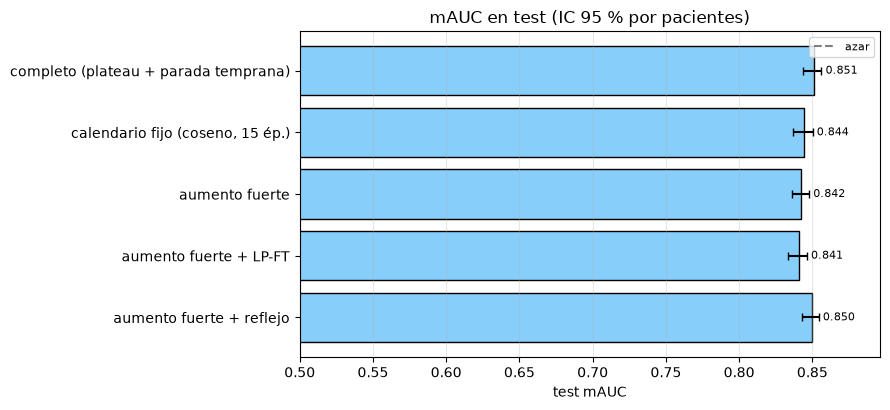

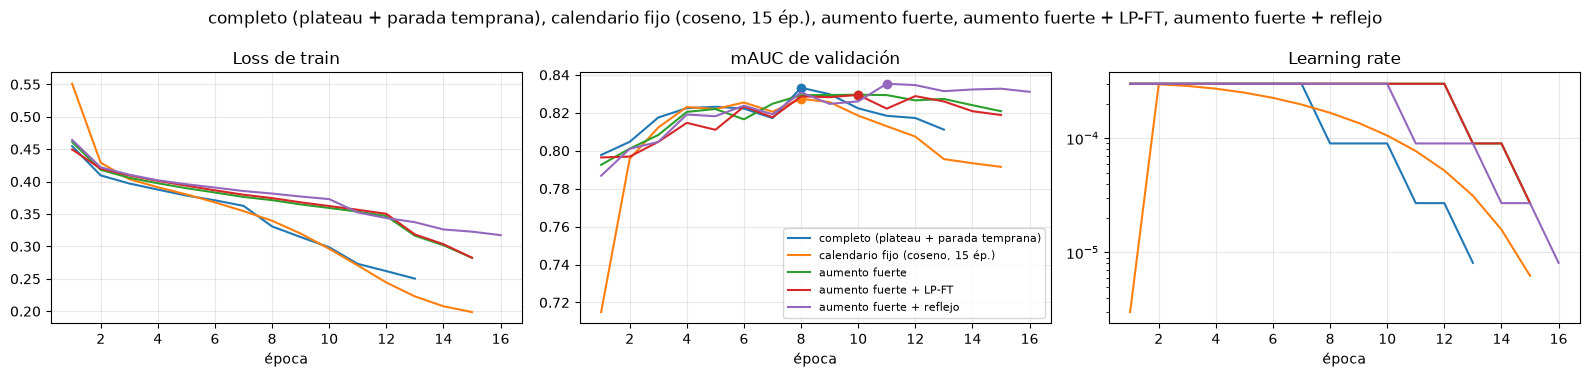

In [42]:
variantes = {
    'completo (plateau + parada temprana)': full,
    'calendario fijo (coseno, 15 ép.)': full_coseno,
    'aumento fuerte': full_fuerte,
    'aumento fuerte + LP-FT': full_lpft,
    'aumento fuerte + reflejo': full_flip,
}
comparar(datos, variantes, referencia='completo (plateau + parada temprana)', por_clase=True)
graficar_curvas(variantes)

### Comparación con la literatura

AUROC por patología en test de nuestros dos mejores modelos frente a los resultados publicados en ChestX-ray14. En **negrita**, el mejor valor de cada fila.

| Patología | Wang et al. (2017) [1] | CheXNet (2017) [2] | Nuestro completo | Nuestro promedio de 4 |
|---|---|---|---|---|
| Atelectasis | 0,700 | 0,8094 | 0,8123 | **0,8215** |
| Cardiomegaly | 0,810 | **0,9248** | 0,9129 | 0,9168 |
| Effusion | 0,759 | 0,8638 | 0,8821 | **0,8871** |
| Infiltration | 0,661 | **0,7345** | 0,7229 | 0,7276 |
| Mass | 0,693 | **0,8676** | 0,8583 | 0,8615 |
| Nodule | 0,669 | 0,7802 | 0,7769 | **0,7858** |
| Pneumonia | 0,658 | 0,7680 | 0,8029 | **0,8095** |
| Pneumothorax | 0,799 | 0,8887 | 0,8849 | **0,8909** |
| Consolidation | 0,703 | 0,7901 | 0,8061 | **0,8072** |
| Edema | 0,805 | 0,8878 | 0,9151 | **0,9186** |
| Emphysema | 0,833 | **0,9371** | 0,9190 | 0,9274 |
| Fibrosis | 0,786 | 0,8047 | 0,8321 | **0,8437** |
| Pleural Thickening | 0,684 | 0,8062 | 0,8235 | **0,8304** |
| Hernia | 0,872 | 0,9164 | **0,9637** | 0,9628 |
| **mAUC (media de 14)** | 0,745 | 0,8414 | 0,8509 | **0,8565** |

**Lectura.** Nuestro promedio de 4 modelos obtiene el mejor mAUC (0,8565 frente a 0,8414 de CheXNet) y el mejor valor en 9 de las 14 patologías. CheXNet gana en *Cardiomegaly, Infiltration, Mass y Emphysema,* y nuestro modelo completo gana en *Hernia*. El modelo completo individual (0,8509) ya supera a CheXNet en el promedio, con la misma arquitectura (DenseNet121).

## Bibliografía

[1] X. Wang, Y. Peng, L. Lu, Z. Lu, M. Bagheri y R. M. Summers. «ChestX-ray8: Hospital-scale chest X-ray database and benchmarks on weakly-supervised classification and localization of common thorax diseases». *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 2017, pp. 2097–2106.

[2] P. Rajpurkar, J. Irvin, K. Zhu, B. Yang, H. Mehta, T. Duan, D. Ding, A. Bagul, C. Langlotz, K. Shpanskaya, M. P. Lungren y A. Y. Ng. «CheXNet: Radiologist-level pneumonia detection on chest X-rays with deep learning». *arXiv preprint* arXiv:1711.05225, 2017.

[3] G. Huang, Z. Liu, L. van der Maaten y K. Q. Weinberger. «Densely connected convolutional networks». *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 2017, pp. 4700–4708.

[4] J. Deng, W. Dong, R. Socher, L.-J. Li, K. Li y L. Fei-Fei. «ImageNet: A large-scale hierarchical image database». *Proceedings of the IEEE Conference on Computer Vision and Pattern Recognition (CVPR)*, 2009, pp. 248–255.

[5] A. Kumar, A. Raghunathan, R. Jones, T. Ma y P. Liang. «Fine-tuning can distort pretrained features and underperform out-of-distribution». *International Conference on Learning Representations (ICLR)*, 2022.

[6] I. Loshchilov y F. Hutter. «Decoupled weight decay regularization». *International Conference on Learning Representations (ICLR)*, 2019.

[7] I. Loshchilov y F. Hutter. «SGDR: Stochastic gradient descent with warm restarts». *International Conference on Learning Representations (ICLR)*, 2017.

[8] T. Fawcett. «An introduction to ROC analysis». *Pattern Recognition Letters*, vol. 27, n.º 8, 2006, pp. 861–874.

[9] B. Efron y R. J. Tibshirani. *An Introduction to the Bootstrap*. Chapman & Hall, 1993.

[10] A. Paszke et al. «PyTorch: An imperative style, high-performance deep learning library». *Advances in Neural Information Processing Systems (NeurIPS)*, vol. 32, 2019.

[11] R. Wightman. «PyTorch Image Models (timm)». GitHub, 2019. https://github.com/huggingface/pytorch-image-models. DOI: 10.5281/zenodo.4414861.

[12] F. Pedregosa et al. «Scikit-learn: Machine learning in Python». *Journal of Machine Learning Research*, vol. 12, 2011, pp. 2825–2830.

[13] «NIH Chest X-ray» (versión de HuggingFace utilizada). *Hugging Face Datasets*. Completar con `DATASET_OWNER/DATASET_NAME` y la URL del notebook. Consultado el 27 de octubre de 2026.